# push_t_book_3 — CEM planning visuals

Book versions of the P75 CEM-planning sequence (`p75b` manim scene).

Two halves:
- **Visualize** (sections 1–4): needs only the saved run data (`iterations.npz`, `config.json`) that
  `p75bb.ipynb` wrote — no model, no env. Start/goal frames are vector-rendered from the states in
  `config.json`; candidate paths are drawn as line collections in the same 512-px world coordinates.
- **Regenerate** (section 5, optional): re-run the instrumented CEM for a different episode / config
  and write the same files. Requires the model + dataset.

Data layout (from `p75bb`):
```
iterations.npz   paths_all (n_steps, N, N_ACTS, 2)  image px (224), y down
                 paths_elite (n_steps, K, N_ACTS, 2)   paths_mean (n_steps, N_ACTS, 2)
                 costs (n_steps, N)   topk_inds (n_steps, K)   cum_sigma (n_steps, N_ACTS, 2)
config.json      agent_xy_img, start_state, goal_state, scale (224/512), CEM config …
```


## 1. Config

In [1]:
from pathlib import Path

# ── Print palette ──────────────────────────────────────────────────────────
CHILL_BROWN = "#948678"
LT_BLUE     = "#5badb6"
ORANGE      = "#eb8423"
FRESH_TAN   = "#f4ebd9"
DEEP_TEAL   = "#063336"      # dark background for the CEM figures
YELLOW      = "#ffd35a"
MAGENTA     = "#ff00ff"
PINK = "#ed5e78"
RED = "#d73b2f"

PALETTE = dict(               # the tan "game frame" look (book_1 / book_2)
    target=CHILL_BROWN, movable=LT_BLUE, effector=ORANGE, background=FRESH_TAN,
    outline=None, frame=CHILL_BROWN, frame_width=1.5,
)
CEM_PALETTE = dict(PALETTE,   # same shapes on the dark CEM background — override freely
    background=DEEP_TEAL,
    frame=CHILL_BROWN,
)

# ── CEM run to visualize ───────────────────────────────────────────────────
# HACKIN   = Path("/home/stephen/Stephencwelch Dropbox/welch_labs/jepa_2/hackin")
HACKIN   = Path("/home/stephen/Stephencwelch Dropbox/welch_labs/jepa_2/hackin")
RUN_DIR  = HACKIN / "p75b" / "ep2167_off25_h5"     # written by p75bb (or section 5 below)

OUT_ROOT = Path("/home/stephen/Stephencwelch Dropbox/welch_labs/ai_book_vol_2/4_jepa/graphics")
OUT_DIR  = OUT_ROOT / "push_t_book_3" / RUN_DIR.name

# ── Path drawing (first viz: all candidates at iteration 0) ────────────────
STEP          = 0           # CEM iteration to draw
N_PATHS       = 100 #500         # how many of the N candidates to draw
PATH_COLOR    = PINK
PATH_ALPHA    = 0.35
PATH_WIDTH    = 0.75         # points
START_DIM     = 0.3        # opacity of the start-frame shapes under the paths (manim used 0.1)
SHOW_START_DOT = True       # dot at the effector start position
START_DOT_COLOR = ORANGE

# ── Export ─────────────────────────────────────────────────────────────────
EXPORT_TRANSPARENT = True   # True: no background rect in the SVG (notebook preview still shows DEEP_TEAL)
FIG_SIZE = 4.0              # inches

import matplotlib.pyplot as plt
plt.rcParams["svg.fonttype"] = "none"


## 2. Load the saved CEM run

In [2]:
import json
import numpy as np
from matplotlib.patches import Polygon, Circle, Rectangle
from matplotlib.collections import LineCollection

d   = np.load(RUN_DIR / "iterations.npz")
cfg = json.load(open(RUN_DIR / "config.json"))
for k in d.files: print(f"{k:12s} {d[k].shape}")

IMG_SIZE = cfg["img_size"]           # 224 — coordinate space of the saved paths
WORLD    = cfg["pusht_native"]       # 512 — coordinate space of env states / our renderer
IMG2WORLD = WORLD / IMG_SIZE

start_state  = np.array(cfg["start_state"])      # (7,)
goal_state   = np.array(cfg["goal_state"])       # (7,)
agent_xy     = np.array(cfg["agent_xy_img"]) * IMG2WORLD     # effector start, world px
N_STEPS, N, N_ACTS, _ = d["paths_all"].shape
K = d["paths_elite"].shape[1]

def paths_world(step, which="all", n=None):
    """(M, N_ACTS+1, 2) world-px polylines for one CEM iteration, start point prepended."""
    p = d[f"paths_{which}"][step]
    if p.ndim == 2: p = p[None]                     # paths_mean is (N_ACTS, 2)
    if n is not None: p = p[:n]
    p = p * IMG2WORLD
    start = np.broadcast_to(agent_xy, (p.shape[0], 1, 2))
    return np.concatenate([start, p], axis=1)

print(f"\nepisode {cfg['episode_idx']}  start t={cfg['start_step']}  goal +{cfg['goal_offset']}   "
      f"{N_STEPS} iters × {N} samples × {N_ACTS} actions, top-{K}")
print("effector start (world px):", agent_xy.round(1))


paths_all    (30, 500, 25, 2)
paths_elite  (30, 30, 25, 2)
paths_mean   (30, 25, 2)
costs        (30, 500)
topk_inds    (30, 30)
cum_sigma    (30, 25, 2)
raw_means    (30, 1, 5, 10)
raw_vars     (30, 1, 5, 10)

episode 2167  start t=50  goal +25   30 iters × 500 samples × 25 actions, top-30
effector start (world px): [ 68.1 352. ]


## 3. Renderer (vector shapes + path collections)

In [3]:
# ── PushT geometry (stable_worldmodel/envs/pusht/env.py) ───────────────────
GOAL_POSE    = np.array([256.0, 256.0, np.pi / 4])
AGENT_RADIUS = 0.375 * 40
_S, _L = 30, 120
_T_OUTLINE = np.array([(-_L/2, 0), (_L/2, 0), (_L/2, _S), (_S/2, _S), (_S/2, _L),
                       (-_S/2, _L), (-_S/2, _S), (-_L/2, _S)], float)

def tee_world_vertices(x, y, angle):
    c, s = np.cos(angle), np.sin(angle)
    return (_T_OUTLINE @ np.array([[c, -s], [s, c]]).T) + (x, y)

def draw_tee(ax, pose, color, alpha=1.0, zorder=1):
    ax.add_patch(Polygon(tee_world_vertices(*pose), closed=True, facecolor=color,
                         edgecolor=color, linewidth=0, alpha=alpha, joinstyle="miter", zorder=zorder))

def setup_axes(ax, palette, draw_bg=True):
    """Transparent axes patch, optional background square, frame box on top, 512-world limits."""
    ax.patch.set_alpha(0)
    if draw_bg:
        ax.add_patch(Rectangle((0, 0), WORLD, WORLD, facecolor=palette["background"],
                               edgecolor="none", zorder=0))
    if palette.get("frame"):
        ax.add_patch(Rectangle((0, 0), WORLD, WORLD, facecolor="none", edgecolor=palette["frame"],
                               linewidth=palette.get("frame_width", 1.5), joinstyle="miter",
                               clip_on=False, zorder=10))
    ax.set_xlim(0, WORLD); ax.set_ylim(WORLD, 0); ax.set_aspect("equal"); ax.axis("off")
    return ax

def draw_state(ax, state, palette, alpha=1.0, show_goal=True, show_effector=True, zorder=1):
    """Shapes only (no background) so they can be layered under/over paths with their own alpha."""
    if show_goal:
        draw_tee(ax, GOAL_POSE, palette["target"], alpha, zorder)
    draw_tee(ax, (state[2], state[3], state[4]), palette["movable"], alpha, zorder + 0.1)
    if show_effector:
        ax.add_patch(Circle((state[0], state[1]), AGENT_RADIUS, facecolor=palette["effector"],
                            edgecolor="none", alpha=alpha, zorder=zorder + 0.2))

def draw_paths(ax, segs, color=PATH_COLOR, alpha=PATH_ALPHA, width=PATH_WIDTH, zorder=3, **kw):
    """segs: (M, P, 2) polylines in world px. color may be one color or a list/array per path."""
    lc = LineCollection(segs, colors=color, linewidths=width, alpha=alpha,
                        capstyle="round", joinstyle="round", zorder=zorder, **kw)
    ax.add_collection(lc)
    return lc

def new_figure(size=FIG_SIZE, palette=CEM_PALETTE, preview_bg=True):
    """Square figure; the figure facecolor shows the background in the notebook even when the
    exported SVG is transparent."""
    fig = plt.figure(figsize=(size, size))
    fig.patch.set_facecolor(palette["background"] if preview_bg else "none")
    ax = fig.add_axes([0.02, 0.02, 0.96, 0.96])
    return fig, ax

def save_svg(fig, path, transparent=EXPORT_TRANSPARENT):
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, transparent=transparent, bbox_inches="tight", pad_inches=0.02)
    print("saved", path)


### Sanity check: start + goal frames from `config.json`
Left: start (what the planner sees). Right: goal frame. Compare against `RUN_DIR/start_img.png` / `goal_img.png`.

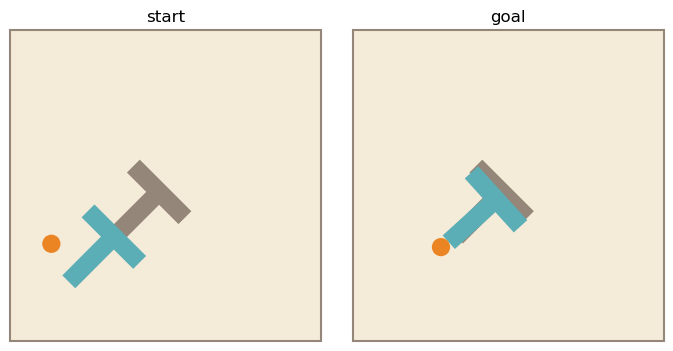

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(7, 3.5))
for ax, st, title in zip(axs, [start_state, goal_state], ["start", "goal"]):
    setup_axes(ax, PALETTE); draw_state(ax, st, PALETTE); ax.set_title(title)
plt.tight_layout(); plt.show()


## 4. Viz 1 — all candidate paths at iteration `STEP` over the start frame

Knobs live in the config cell (`PATH_COLOR`, `PATH_ALPHA`, `PATH_WIDTH`, `START_DIM`, …) but you can
also override them inline here while noodling.

saved /home/stephen/Stephencwelch Dropbox/welch_labs/ai_book_vol_2/4_jepa/graphics/push_t_book_3/ep2167_off25_h5/viz1_paths_step00_n100.svg


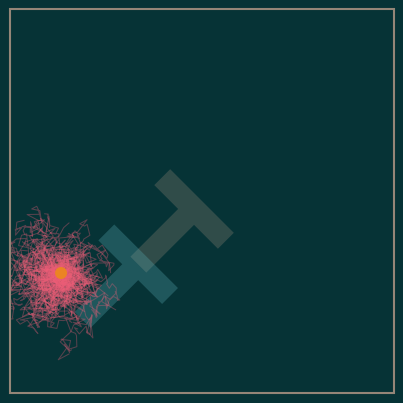

In [5]:
segs = paths_world(STEP, "all", N_PATHS)                 # (N_PATHS, 26, 2)

fig, ax = new_figure()
setup_axes(ax, CEM_PALETTE, draw_bg=not EXPORT_TRANSPARENT)
draw_state(ax, start_state, CEM_PALETTE, alpha=START_DIM)
draw_paths(ax, segs, color=PATH_COLOR, alpha=PATH_ALPHA, width=PATH_WIDTH)
if SHOW_START_DOT:
    ax.add_patch(Circle(agent_xy, 8, facecolor=START_DOT_COLOR, edgecolor="none", zorder=5000))

save_svg(fig, OUT_DIR / f"viz1_paths_step{STEP:02d}_n{N_PATHS}.svg")
plt.show()


### Quick variations
A small grid to compare alpha / width / color choices side by side before committing.

In [6]:
# variants = [
#     dict(color=MAGENTA,  alpha=0.10, width=0.6),
#     dict(color=MAGENTA,  alpha=0.25, width=0.6),
#     dict(color=YELLOW,   alpha=0.15, width=0.5),
#     dict(color=LT_BLUE,  alpha=0.20, width=0.8),
# ]
# fig, axs = plt.subplots(1, len(variants), figsize=(3.2 * len(variants), 3.2))
# fig.patch.set_facecolor(CEM_PALETTE["background"])
# for ax, v in zip(axs, variants):
#     setup_axes(ax, CEM_PALETTE, draw_bg=True)
#     draw_state(ax, start_state, CEM_PALETTE, alpha=START_DIM)
#     draw_paths(ax, segs, **v)
#     ax.set_title(f"{v['color']}  α={v['alpha']}  w={v['width']}", fontsize=8, color=FRESH_TAN)
# plt.show()


---
## 5. (Optional) Regenerate CEM data for another episode / config

Mirrors `p75bb` sections 1–2: builds the world at a dataset episode, runs the instrumented CEM solver,
projects candidates to image px, and writes `iterations.npz` + `config.json` + `start_img.png` /
`goal_img.png` into a new `RUN_DIR`. Then set `RUN_DIR` in the config cell to it and re-run from section 2.
Needs the model + dataset (same env as `push_t_book_2`).

In [7]:
import warnings, time
warnings.filterwarnings("ignore", category=UserWarning)
from copy import deepcopy
from collections import defaultdict
from typing import Any
import torch, gymnasium as gym
from sklearn.preprocessing import StandardScaler
from torchvision.transforms import v2 as transforms
from PIL import Image
import stable_worldmodel as swm

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# ── run config ─────────────────────────────────────────────────────────────
EPISODE_IDX, START_STEP, GOAL_OFFSET = 2167, 50, 25
HORIZON, ACTION_BLOCK = 5, 5
NUM_SAMPLES, N_STEPS_CEM, TOPK, VAR_SCALE, SEED = 500, 30, 30, 1.0, 42
NEW_RUN_DIR = HACKIN / "push_t_book_3" / "runs" / f"ep{EPISODE_IDX}_s{START_STEP}_off{GOAL_OFFSET}_h{HORIZON}"
assert HORIZON * ACTION_BLOCK == GOAL_OFFSET, "plan length should equal goal offset"

# ── env + dataset + scaler + px/action calibration ─────────────────────────
ds = swm.data.HDF5Dataset(name="pusht_expert_train", keys_to_cache=["action", "proprio", "state"])
ep_starts = np.concatenate([[0], np.cumsum(ds.lengths)]).astype(np.int64)

all_actions = ds.get_col_data("action")
if all_actions.ndim == 3: all_actions = all_actions.reshape(-1, all_actions.shape[-1])
all_actions = all_actions[~np.isnan(all_actions).any(axis=1)]
action_scaler = StandardScaler().fit(all_actions)

states_raw, actions_raw = ds.get_col_data("state"), ds.get_col_data("action")
a_per_row = actions_raw.sum(axis=1) if actions_raw.ndim == 3 else actions_raw
r0, l0 = int(ep_starts[0]), int(ds.lengths[0])
xy, ac = states_raw[r0:r0+l0, :2].astype(float), a_per_row[r0:r0+l0].astype(float)
ok = ~(np.isnan(xy).any(1) | np.isnan(ac).any(1)); xy, ac = xy[ok], ac[ok]
dl, ac = np.diff(xy, axis=0), ac[:-1]
act_scale = np.array([(ac[:, 0] @ dl[:, 0]) / (ac[:, 0] @ ac[:, 0]),
                      (ac[:, 1] @ dl[:, 1]) / (ac[:, 1] @ ac[:, 1])])
IMG_SIZE_RUN = 224; SCALE = IMG_SIZE_RUN / WORLD
print("act_scale (px / unit):", act_scale.round(3))

img_transform = transforms.Compose([
    transforms.ToImage(), transforms.ToDtype(torch.float32, scale=True),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    transforms.Resize(size=IMG_SIZE_RUN),
])

import sys
sys.path.append(str(HACKIN / "le-wm"))      # checkpoint pickle references `jepa` from the le-wm repo
cost_model = swm.policy.AutoCostModel("pusht/lewm").to(DEVICE).eval()
cost_model.requires_grad_(False); cost_model.interpolate_pos_encoding = True
CALLABLES = [{"method": "_set_state",      "args": {"state":      {"value": "state"}}},
             {"method": "_set_goal_state", "args": {"goal_state": {"value": "state"}}}]


act_scale (px / unit): [40.05 39.55]


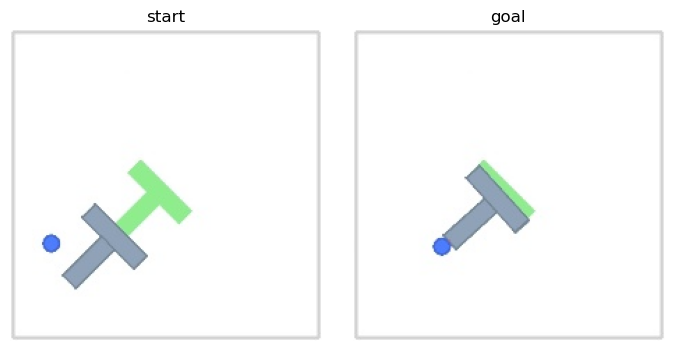

In [8]:
# ── policy / solver / world (current stable_worldmodel API) ────────────────
from stable_worldmodel.world.world import _extract_init_goal, _apply_callables
from stable_worldmodel.solver.callbacks import Callback

class CEMRecorder(Callback):
    """Keeps full per-iteration tensors (CPU) in the same layout the old instrumented loop produced."""
    KEYS = ["candidates", "costs", "topk_inds", "topk_candidates", "means", "vars"]
    def reset(self):
        super().reset(); self.rec = {k: [] for k in self.KEYS}
    def __call__(self, **s):
        for k, src in zip(self.KEYS, ["candidates", "costs", "topk_inds", "topk_candidates", "mean", "var"]):
            self.rec[k].append(s[src].detach().float().cpu())

recorder = CEMRecorder()
plan_config = swm.PlanConfig(horizon=HORIZON, receding_horizon=HORIZON, action_block=ACTION_BLOCK)
solver = swm.solver.CEMSolver(model=cost_model, batch_size=1, num_samples=NUM_SAMPLES,
                              var_scale=VAR_SCALE, n_steps=N_STEPS_CEM, topk=TOPK,
                              device=DEVICE, seed=SEED, callbacks=[recorder])
policy = swm.policy.WorldModelPolicy(solver=solver, config=plan_config,
                                     process={"action": action_scaler},
                                     transform={"pixels": img_transform, "goal": img_transform})
world = swm.World(env_name="swm/PushT-v1", num_envs=1, max_episode_steps=2 * GOAL_OFFSET,
                  image_shape=(IMG_SIZE_RUN, IMG_SIZE_RUN))
world.set_policy(policy)

# ── put the world at the dataset episode (same steps as World._evaluate_from_dataset) ──
init_state, goal_state, _ = _extract_init_goal(ds, [EPISODE_IDX], [START_STEP], GOAL_OFFSET)
world.reset(seed=init_state.get("seed"))
merged = {**init_state, **goal_state}
_apply_callables(world.envs.envs[0].unwrapped, CALLABLES, {k: v[0] for k, v in merged.items()})
shape_prefix = world.infos["pixels"].shape[:2]
for src in (init_state, goal_state):
    for k, v in src.items():
        if k in world.infos or k in goal_state:
            world.infos[k] = np.broadcast_to(v[:, None, ...], shape_prefix + v.shape[1:]).copy()

canvas   = init_state["pixels"][0]        # (224, 224, 3) uint8 — the frame the planner sees
goal_img = goal_state["goal"][0]
row0 = ep_starts[EPISODE_IDX]
run_start_state = ds[row0 + START_STEP]["state"].squeeze(0).cpu().numpy()
run_goal_state  = ds[row0 + START_STEP + GOAL_OFFSET]["state"].squeeze(0).cpu().numpy()
agent_xy_img    = run_start_state[:2] * SCALE

fig, axs = plt.subplots(1, 2, figsize=(7, 3.5))
axs[0].imshow(canvas); axs[0].set_title("start"); axs[0].axis("off")
axs[1].imshow(goal_img); axs[1].set_title("goal"); axs[1].axis("off")
plt.tight_layout(); plt.show()

In [9]:
# ── run CEM; the recorder captures every iteration ─────────────────────────
t0 = time.time()
info_dict = world.policy._prepare_info(world.infos)
out = solver.solve(info_dict)
history = recorder.rec
print(f"CEM: {time.time()-t0:.1f}s   {len(history['costs'])} iterations recorded   "
      f"final best cost {history['costs'][-1].min().item():.4f}")

N_ACTS_RUN, A_DIM = HORIZON * ACTION_BLOCK, 2
def candidates_to_image_xy(cands, start_xy_img):
    a = cands.detach().cpu().numpy().reshape(cands.shape[0], N_ACTS_RUN, A_DIM)
    a = action_scaler.inverse_transform(a.reshape(-1, A_DIM)).reshape(-1, N_ACTS_RUN, A_DIM)
    return np.cumsum(a * act_scale * SCALE, axis=1) + start_xy_img[None, None, :]

P_all, P_elite, P_mean, C, TK, CS = [], [], [], [], [], []
for it in range(N_STEPS_CEM):
    P_all.append(candidates_to_image_xy(history["candidates"][it][0], agent_xy_img))
    P_elite.append(candidates_to_image_xy(history["topk_candidates"][it][0], agent_xy_img))
    P_mean.append(candidates_to_image_xy(history["means"][it][0:1], agent_xy_img)[0])
    C.append(history["costs"][it][0].numpy()); TK.append(history["topk_inds"][it][0].numpy())
    sig = history["vars"][it][0].numpy().reshape(N_ACTS_RUN, A_DIM) * action_scaler.scale_ * act_scale * SCALE
    CS.append(np.sqrt(np.cumsum(sig ** 2, axis=0)))

NEW_RUN_DIR.mkdir(parents=True, exist_ok=True)
np.savez_compressed(NEW_RUN_DIR / "iterations.npz",
    paths_all=np.stack(P_all).astype(np.float32), paths_elite=np.stack(P_elite).astype(np.float32),
    paths_mean=np.stack(P_mean).astype(np.float32), costs=np.stack(C).astype(np.float32),
    topk_inds=np.stack(TK).astype(np.int32), cum_sigma=np.stack(CS).astype(np.float32),
    raw_means=torch.stack(history["means"]).numpy().astype(np.float32),
    raw_vars=torch.stack(history["vars"]).numpy().astype(np.float32))
json.dump({
    "episode_idx": EPISODE_IDX, "start_step": START_STEP, "goal_offset": GOAL_OFFSET,
    "horizon": HORIZON, "action_block": ACTION_BLOCK, "n_acts_per_plan": N_ACTS_RUN,
    "num_samples": NUM_SAMPLES, "n_steps": N_STEPS_CEM, "topk": TOPK, "var_scale": VAR_SCALE, "seed": SEED,
    "img_size": IMG_SIZE_RUN, "pusht_native": WORLD, "scale": float(SCALE),
    "agent_xy_img": agent_xy_img.tolist(), "start_state": run_start_state.tolist(), "goal_state": run_goal_state.tolist(),
    "act_scale": act_scale.tolist(), "action_scaler_mean": action_scaler.mean_.tolist(),
    "action_scaler_scale": action_scaler.scale_.tolist(),
}, open(NEW_RUN_DIR / "config.json", "w"), indent=2)
Image.fromarray(canvas).save(NEW_RUN_DIR / "start_img_raw.png")
Image.fromarray(goal_img).save(NEW_RUN_DIR / "goal_img_raw.png")
torch.save(history, NEW_RUN_DIR / "cem_history.pt")      # standardized candidates, for WM rollouts later
print("saved →", NEW_RUN_DIR, "\nset RUN_DIR to this and re-run from section 2")


CEM solve time: 1.2594 seconds
CEM: 1.3s   30 iterations recorded   final best cost 3.4703
saved → /home/stephen/Stephencwelch Dropbox/welch_labs/jepa_2/hackin/push_t_book_3/runs/ep2167_s50_off25_h5 
set RUN_DIR to this and re-run from section 2


## Render a specific path

step 0, candidate 45: cost 261.9353   waypoints at path indices [0, 5, 10, 15, 20, 25]
saved /home/stephen/Stephencwelch Dropbox/welch_labs/ai_book_vol_2/4_jepa/graphics/push_t_book_3/ep2167_off25_h5/viz2_highlight_step00_idx045.svg


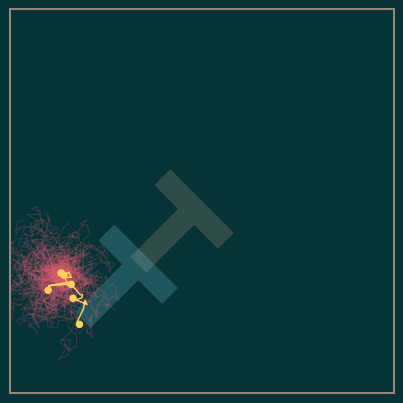

In [17]:
# ── Viz 2: one highlighted candidate over the dimmed cloud ─────────────────
HL_STEP        = 0        # CEM iteration
HL_IDX         = 45       # candidate index (manim: path_index=45 → wm_rollouts/iter_000/sample_002)
HL_COLOR       = YELLOW
HL_WIDTH       = 1.0
HL_ALPHA       = 1.0
CLOUD_ALPHA    = 0.2     # all other candidates (manim faded them to 0.05)
WAYPOINT_EVERY = 5        # dot every N actions along the highlighted path (0, 5, 10, …, 25)
WAYPOINT_R     = 5.0      # world px
WAYPOINT_COLOR = YELLOW

segs    = paths_world(HL_STEP, "all", N_PATHS)          # (N_PATHS, 26, 2)
hl_path = paths_world(HL_STEP, "all")[HL_IDX]           # (26, 2) incl. start point
wp_idx  = list(range(0, hl_path.shape[0], WAYPOINT_EVERY))
print(f"step {HL_STEP}, candidate {HL_IDX}: cost {d['costs'][HL_STEP, HL_IDX]:.4f}   "
      f"waypoints at path indices {wp_idx}")

fig, ax = new_figure()
setup_axes(ax, CEM_PALETTE, draw_bg=not EXPORT_TRANSPARENT)
draw_state(ax, start_state, CEM_PALETTE, alpha=START_DIM)
draw_paths(ax, np.delete(segs, HL_IDX, axis=0), color=PATH_COLOR, alpha=CLOUD_ALPHA, width=PATH_WIDTH, zorder=3)
draw_paths(ax, hl_path[None], color=HL_COLOR, alpha=HL_ALPHA, width=HL_WIDTH, zorder=4)
for i in wp_idx:
    ax.add_patch(Circle(hl_path[i], WAYPOINT_R, facecolor=WAYPOINT_COLOR, edgecolor="none", zorder=5))

save_svg(fig, OUT_DIR / f"viz2_highlight_step{HL_STEP:02d}_idx{HL_IDX:03d}.svg")
plt.show()

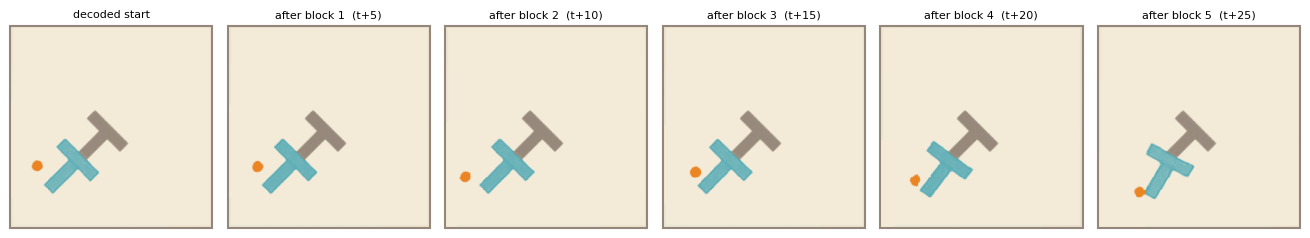

saved /home/stephen/Stephencwelch Dropbox/welch_labs/ai_book_vol_2/4_jepa/graphics/push_t_book_3/ep2167_off25_h5/highlight_step00_idx045


In [18]:
# ── Viz 2b: imagined WM rollout along the highlighted candidate ────────────
import sys, torch, torch.nn as nn, scipy.ndimage as ndi
from PIL import Image
sys.path.append(str(HACKIN / "le-wm"))
from decoder import CLSDecoder

LEWM_DIR      = HACKIN / "le-wm"
RECOLOR_SIGMA = 45.0
WM_HISTORY    = 3
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# decoder + adapter (Matthew's weights)
decoder_mc = CLSDecoder(cls_dim=192, img_size=224, patch_size=14, dim=256, heads=8, depth=3)
decoder_mc.load_state_dict(torch.load(LEWM_DIR / "decoder_mc_10_epochs.pt", weights_only=True, map_location="cpu"), strict=False)
decoder_mc = decoder_mc.to(DEVICE).eval(); decoder_mc.requires_grad_(False)
adapter = nn.Sequential(nn.Linear(192, 512), nn.GELU(), nn.Linear(512, cost_model.encoder.config.hidden_size))
adapter.load_state_dict(torch.load(LEWM_DIR / "adapter_weights.pt", weights_only=True, map_location="cpu"), strict=False)
adapter = adapter.to(DEVICE).eval(); adapter.requires_grad_(False)

@torch.no_grad()
def encode_frame(rgb_uint8):
    px = img_transform(rgb_uint8).unsqueeze(0).unsqueeze(0).to(DEVICE)
    return cost_model.encode({"pixels": px})["emb"][:, 0]

@torch.no_grad()
def decode_emb(emb):
    img = decoder_mc(adapter(emb))[0].permute(1, 2, 0).cpu().numpy()
    img = (img - img.min()) / (img.max() - img.min() + 1e-8)
    return np.round(img * 255).astype(np.uint8)

@torch.no_grad()
def predict_next(emb_hist, act_hist):
    e = torch.stack(emb_hist[-WM_HISTORY:], 1); a = torch.stack(act_hist[-WM_HISTORY:], 1)
    return cost_model.predict(e, cost_model.action_encoder(a))[:, -1]

# ── recolor (decoder-sampled source anchors → print palette) ───────────────
def _hex(h): h = h.lstrip("#"); return np.array([int(h[i:i+2], 16) for i in (0, 2, 4)], np.float32)
DECODED_PALETTE = {
    "src_bg": np.array([203,214,226],np.float32), "src_frame_border": np.array([156,164,178],np.float32),
    "src_target_fill": np.array([88,201,112],np.float32), "src_movable_fill": np.array([92,121,147],np.float32),
    "src_effector_fill": np.array([15,69,215],np.float32), "src_target_outline": np.array([87,172,115],np.float32),
    "src_movable_outline": np.array([53,77,103],np.float32), "src_effector_outline": np.array([14,61,175],np.float32),
    "r_target_fill": 45.0, "r_movable_fill": 22.0, "r_effector_fill": 55.0, "min_component_size": 10,
    "tgt_bg": _hex(PALETTE["background"]), "tgt_frame_border": _hex(PALETTE["background"]),
    "tgt_target_fill": _hex(PALETTE["target"]), "tgt_target_outline": _hex(PALETTE["target"]),
    "tgt_movable_fill": _hex(PALETTE["movable"]), "tgt_movable_outline": _hex(PALETTE["movable"]),
    "tgt_effector_fill": _hex(PALETTE["effector"]), "tgt_effector_outline": _hex(PALETTE["effector"]),
}
_SHAPES = [(1,"src_target_fill","src_target_outline","tgt_target_fill","tgt_target_outline"),
           (2,"src_movable_fill","src_movable_outline","tgt_movable_fill","tgt_movable_outline"),
           (3,"src_effector_fill","src_effector_outline","tgt_effector_fill","tgt_effector_outline")]
def _keep(mask, m):
    lab, n = ndi.label(mask)
    if n == 0: return mask
    keep = np.zeros(n+1, bool); keep[1:] = ndi.sum_labels(mask, lab, range(1, n+1)) >= m
    return keep[lab]
def _segment(img, p):
    ball = lambda a, r: np.linalg.norm(img - a, axis=-1) < r; m = int(p["min_component_size"])
    lbl = np.zeros(img.shape[:2], np.int32)
    lbl[_keep(ball(p["src_target_fill"], p["r_target_fill"]), m)] = 1
    lbl[_keep(ball(p["src_movable_fill"], p["r_movable_fill"]), m)] = 2
    lbl[_keep(ball(p["src_effector_fill"], p["r_effector_fill"]), m)] = 3
    if (lbl == 0).all(): return lbl
    _, idx = ndi.distance_transform_edt(lbl == 0, return_indices=True); return lbl[idx[0], idx[1]]
def recolor_pusht(frame, p=DECODED_PALETTE, sigma=RECOLOR_SIGMA):
    img = frame.astype(np.float32); lbl = _segment(img, p)
    sf, so, tf, to = (np.empty_like(img) for _ in range(4))
    for v, a, b, c, e in _SHAPES:
        m = lbl == v
        if m.any(): sf[m], so[m], tf[m], to[m] = p[a], p[b], p[c], p[e]
    if (lbl == 0).any():
        m = lbl == 0; sf[m] = so[m] = p["src_bg"]; tf[m] = to[m] = p["tgt_bg"]
    src = np.stack([sf, so, np.broadcast_to(p["src_bg"], img.shape), np.broadcast_to(p["src_frame_border"], img.shape)], -2)
    tgt = np.stack([tf, to, np.broadcast_to(p["tgt_bg"], img.shape), np.broadcast_to(p["tgt_frame_border"], img.shape)], -2)
    w = np.exp(-((img[..., None, :] - src) ** 2).sum(-1) / (2 * sigma * sigma)); w /= w.sum(-1, keepdims=True)
    return np.clip((w[..., None] * tgt).sum(-2), 0, 255).astype(np.uint8)

# ── recover standardized action blocks for the highlighted candidate ───────
# inverse of candidates_to_image_xy: image-px deltas → env actions → standardized → (H, A_BLOCK*2)
path_img   = d["paths_all"][HL_STEP, HL_IDX]                            # (25, 2) image px
deltas_img = np.diff(np.concatenate([np.array(cfg["agent_xy_img"])[None], path_img]), axis=0)
a_env      = deltas_img / (np.array(cfg["act_scale"]) * cfg["scale"])     # (25, 2) env-scale
a_std      = (a_env - np.array(cfg["action_scaler_mean"])) / np.array(cfg["action_scaler_scale"])
blocks     = torch.from_numpy(a_std.reshape(cfg["horizon"], -1).astype(np.float32)).to(DEVICE)  # (5, 10)

# ── roll the world model along it ──────────────────────────────────────────
row0 = ep_starts[cfg["episode_idx"]]
start_frame = ds[row0 + cfg["start_step"]]["pixels"].squeeze(0).permute(1, 2, 0).cpu().numpy()  # (224,224,3)
first_emb = encode_frame(start_frame)
emb_hist, act_hist = [first_emb], []
for k in range(blocks.shape[0]):
    act_hist.append(blocks[k:k+1]); emb_hist.append(predict_next(emb_hist, act_hist))
wm_frames = [recolor_pusht(decode_emb(e)) for e in emb_hist]           # 6 frames: decoded start + 5 waypoints

hl_dir = OUT_DIR / f"highlight_step{HL_STEP:02d}_idx{HL_IDX:03d}"; hl_dir.mkdir(parents=True, exist_ok=True)
for k, fr in enumerate(wm_frames):
    Image.fromarray(fr).save(hl_dir / f"wm_frame_{k:02d}.png")
Image.fromarray(start_frame).save(hl_dir / "start_frame_raw.png")

fig, axs = plt.subplots(1, len(wm_frames), figsize=(2.2 * len(wm_frames), 2.4))
for k, (ax, fr) in enumerate(zip(axs, wm_frames)):
    setup_axes(ax, PALETTE); ax.imshow(fr, extent=(0, WORLD, WORLD, 0), interpolation="bilinear", zorder=1)
    ax.set_title("decoded start" if k == 0 else f"after block {k}  (t+{k*cfg['action_block']})", fontsize=8)
plt.tight_layout(); plt.show()
print("saved", hl_dir)

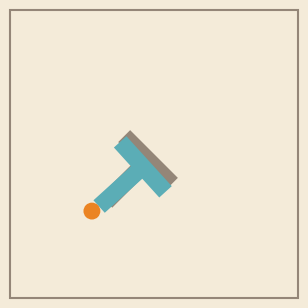

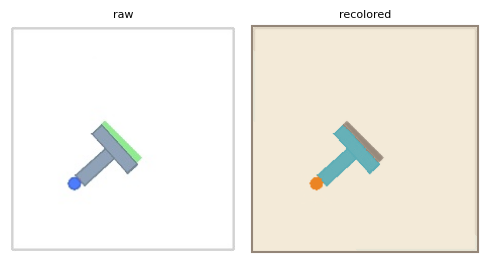

saved goal_vector.svg/.png, goal_frame_raw.png, goal_frame_recolored.png → /home/stephen/Stephencwelch Dropbox/welch_labs/ai_book_vol_2/4_jepa/graphics/push_t_book_3/ep2167_off25_h5/highlight_step00_idx045


In [21]:
# ── goal frame for this planning problem ───────────────────────────────────
GOAL_PALETTE = PALETTE        # tan "game frame" look; use CEM_PALETTE for the dark version
hl_dir = OUT_DIR / f"highlight_step{HL_STEP:02d}_idx{HL_IDX:03d}"; hl_dir.mkdir(parents=True, exist_ok=True)

# 1. vector render from goal_state (config.json) → SVG + PNG
fig, ax = new_figure(size=3.0, palette=GOAL_PALETTE)
setup_axes(ax, GOAL_PALETTE, draw_bg=True)
# draw_state(ax, goal_state, GOAL_PALETTE)
draw_state(ax, np.array(cfg["goal_state"]), GOAL_PALETTE)
fig.savefig(hl_dir / "goal_vector.svg", transparent=True, bbox_inches="tight", pad_inches=0.02)
fig.savefig(hl_dir / "goal_vector.png", dpi=300, transparent=True, bbox_inches="tight", pad_inches=0.02)
plt.show()

# 2. the actual pixel frame the planner encodes (dataset row start+offset), recolored to the palette
row0 = ep_starts[cfg["episode_idx"]]
goal_px = ds[row0 + cfg["start_step"] + cfg["goal_offset"]]["pixels"].squeeze(0).permute(1, 2, 0).cpu().numpy()
RAW_SRC = {  # pygame-render source anchors (p75bb DEFAULT_PALETTE_3), targets from the print palette
    **{k: v for k, v in DECODED_PALETTE.items() if k.startswith("tgt_") or k.startswith("r_") or k == "min_component_size"},
    "src_bg": np.array([255,255,255],np.float32), "src_frame_border": np.array([205,205,205],np.float32),
    "src_target_fill": np.array([130,236,138],np.float32), "src_movable_fill": np.array([130,153,172],np.float32),
    "src_effector_fill": np.array([70,119,246],np.float32), "src_target_outline": np.array([170,212,161],np.float32),
    "src_movable_outline": np.array([143,159,179],np.float32), "src_effector_outline": np.array([83,107,195],np.float32),
}
goal_recolored = recolor_pusht(goal_px, p=RAW_SRC, sigma=40)
Image.fromarray(goal_px).save(hl_dir / "goal_frame_raw.png")
Image.fromarray(goal_recolored).save(hl_dir / "goal_frame_recolored.png")

fig, axs = plt.subplots(1, 2, figsize=(5, 2.6))
axs[0].imshow(goal_px); axs[0].set_title("raw", fontsize=8); axs[0].axis("off")
setup_axes(axs[1], GOAL_PALETTE); axs[1].imshow(goal_recolored, extent=(0, WORLD, WORLD, 0), zorder=1); axs[1].set_title("recolored", fontsize=8)
plt.tight_layout(); plt.show()
print("saved goal_vector.svg/.png, goal_frame_raw.png, goal_frame_recolored.png →", hl_dir)